# 25083010035_Ika Acha Tabarani

# Volume Kedua Lambung Perahu Katamaran

Soal
hitung volume kedua lambung kapal dari gambar (tampak atas dan tampak samping).

Asumsi
- 1 kotak grid = 5 cm × 5 cm (1 titik-titik = 1 cm)
- Lantai kapal datar (tanpa keel), jadi tampak depan berupa persegi panjang
- Volume reserve buoyancy (ujung kiri dan ujung kanan lambung) tidak dihitung
- Dua lambung identik, jadi hitung satu lambung lalu kalikan 2

Daerah yang dihitung:
dari garis lengkung di kiri sampai garis tegak di kanan, sepanjang 16 kotak (80 cm).

Metode: 
luas penampang di tiap posisi = lebar × kedalaman 
Volume = integral luas penampang sepanjang lambung
dihitung dengan aturan trapesium dan Simpson 1/3.

## 1. Data hasil pengukuran dari gambar

Posisi `x` diukur dari garis lengkung kiri (x = 0) sampai garis tegak kanan (x = 16), tiap 1 kotak.
- Lebar: dari tampak atas
- Kedalaman: dari tampak samping (garis dek sampai dasar lambung)

In [1]:
import numpy as np
import pandas as pd

KOTAK_CM = 5  # 1 kotak = 5 cm

# posisi dihitung dari garis lengkung kiri
x_kotak = np.arange(0, 17)

# lebar lambung dari tampak atas
lebar_kotak = np.array([1.70, 1.90, 2.00, 2.04, 2.04, 2.04, 2.04, 2.04, 2.04,
                        2.04, 2.04, 2.04, 2.04, 1.75, 1.45, 1.20, 0.95])

# kedalaman lambung dari tampak samping
dalam_kotak = np.array([1.70, 2.15, 2.50, 2.57, 2.57, 2.57, 2.57, 2.57, 2.57,
                        2.57, 2.57, 2.57, 2.57, 2.57, 2.57, 2.57, 2.57])

df = pd.DataFrame({
    "x (kotak)": x_kotak,
    "lebar (kotak)": lebar_kotak,
    "dalam (kotak)": dalam_kotak,
})
df["x (cm)"] = df["x (kotak)"] * KOTAK_CM
df["lebar (cm)"] = df["lebar (kotak)"] * KOTAK_CM
df["dalam (cm)"] = df["dalam (kotak)"] * KOTAK_CM
df["luas penampang (cm²)"] = df["lebar (cm)"] * df["dalam (cm)"]
df

,x (kotak),lebar (kotak),dalam (kotak),x (cm),lebar (cm),dalam (cm),luas penampang (cm²)
0,0,1.70,1.70,0,8.50,8.50,72.2500
1,1,1.90,2.15,5,9.50,10.75,102.1250
2,2,2.00,2.50,10,10.00,12.50,125.0000
3,3,2.04,2.57,15,10.20,12.85,131.0700
4,4,2.04,2.57,20,10.20,12.85,131.0700
5,5,2.04,2.57,25,10.20,12.85,131.0700
6,6,2.04,2.57,30,10.20,12.85,131.0700
7,7,2.04,2.57,35,10.20,12.85,131.0700
8,8,2.04,2.57,40,10.20,12.85,131.0700
9,9,2.04,2.57,45,10.20,12.85,131.0700


## 2. Integrasi numerik

In [2]:
x = df["x (cm)"].values
A = df["luas penampang (cm²)"].values

# Aturan trapesium
V_trap = np.trapz(A, x) if hasattr(np, "trapz") else np.trapezoid(A, x)

# Aturan Simpson 1/3
h = x[1] - x[0]
V_simp = h/3 * (A[0] + A[-1] + 4*A[1:-1:2].sum() + 2*A[2:-1:2].sum())

print(f"Volume 1 lambung (trapesium)  : {V_trap:,.0f} cm³ = {V_trap/1000:.2f} liter")
print(f"Volume 1 lambung (Simpson 1/3): {V_simp:,.0f} cm³ = {V_simp/1000:.2f} liter")

Volume 1 lambung (trapesium)  : 9,436 cm³ = 9.44 liter
Volume 1 lambung (Simpson 1/3): 9,447 cm³ = 9.45 liter


## 3. Volume kedua lambung

In [3]:
V_total = 2 * V_simp
print(f"Volume kedua lambung = {V_total:,.0f} cm³")
print(f"                     = {V_total/1000:.2f} liter")
print(f"                     = {V_total/1e6:.4f} m³")

Volume kedua lambung = 18,895 cm³
                     = 18.89 liter
                     = 0.0189 m³


## 4. Cek sederhana dan visualisasi

Luas tampak atas bagian yang dihitung: 751 cm²
Cek kasar (luas x 12,85 cm)            : 9,646 cm³


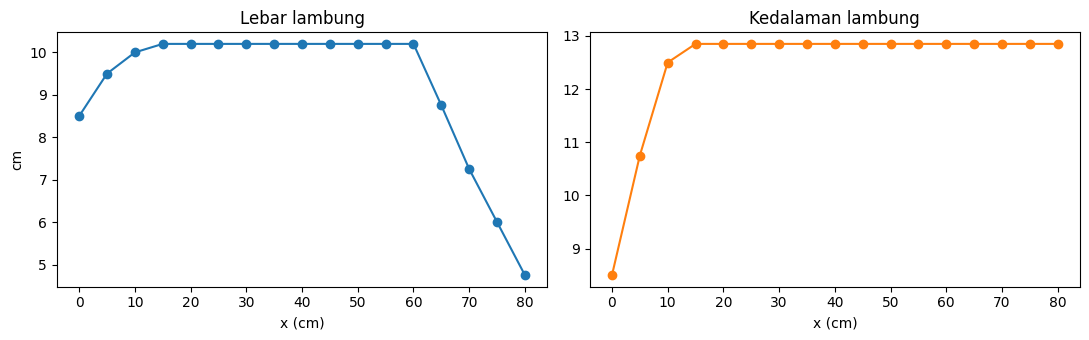

In [4]:
import matplotlib.pyplot as plt

# cek kasar: luas tampak atas x kedalaman rata-rata
luas_atas = np.trapezoid(df["lebar (cm)"], x) if hasattr(np, "trapezoid") else np.trapz(df["lebar (cm)"], x)
print(f"Luas tampak atas bagian yang dihitung: {luas_atas:,.0f} cm²")
print(f"Cek kasar (luas x 12,85 cm)            : {luas_atas*12.85:,.0f} cm³")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(x, df["lebar (cm)"], marker="o"); ax[0].set_title("Lebar lambung"); ax[0].set_xlabel("x (cm)"); ax[0].set_ylabel("cm")
ax[1].plot(x, df["dalam (cm)"], marker="o", color="tab:orange"); ax[1].set_title("Kedalaman lambung"); ax[1].set_xlabel("x (cm)")
plt.tight_layout(); plt.show()